# <center>⚖️ Лекция 10. Этика ИИ, риски и итоги курса</center>
## <center>人工智能伦理与课程总结</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 5 — Развёртывание проектов ИИ и комплексная подготовка · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. объяснять механику предвзятости ИИ: перекошенные данные → перекошенная модель, и называть известные публичные кейсы;<br>2. различать уровни чувствительности данных и применять принцип минимума;<br>3. распознавать дипфейки и ИИ-фишинг по признакам и знать правило «второго канала»;<br>4. описывать риск-подход регуляторов (EU AI Act, правила КНР) и требование маркировки генеративного контента;<br>5. выбирать паттерн «человека в контуре» под уровень риска и формулировать ответственность;<br>6. видеть карту курса целиком и составить план своего развития после него.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Предвзятость: механика и кейсы <i>(20 мин)</i><br>• Приватность данных: три уровня <i>(10 мин)</i><br>• Дипфейки и ИИ-фишинг <i>(10 мин)</i><br>• Регулирование: EU AI Act и правила КНР <i>(10 мин)</i><br>• Человек в контуре и ответственность <i>(10 мин)</i><br>• Карта курса, дорожки развития, итоговый проект <i>(20 мин)</i><br>• Итоговый тест курса <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> Курс «Прикладные технологии ИИ» (10 лекций + 10 практик).
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


# Этика искусственного интеллекта (45–70 мин)

ИИ — мощный инструмент, но его использование несёт серьёзные риски. Разработчик обязан о них знать.

### ⚖️ Ключевые этические проблемы

1. **Предвзятость данных (数据偏见):** Если в данных для обучения распознавания лиц почти нет людей определённой этнической группы, модель будет хуже их распознавать или ошибаться. *Модель повторяет перекосы общества, отражённые в данных.*
2. **Приватность (隐私):** Использование персональных данных (фото, голос, переписки) для обучения моделей без явного согласия людей.
3. **Дипфейки (深度伪造):** Создание поддельных видео или аудио с использованием ИИ для мошенничества или клеветы.
4. **Авторские права (版权):** Кто владеет текстом или картинкой, сгенерированной ИИ на основе чужих защищённых работ?
5. **Ответственность (责任):** Если автономный автомобиль совершит ДТП или медицинский ИИ поставит неверный диагноз, кто виноват: разработчик, владелец или сама модель?
6. **Академическая честность (学术诚信):** Использование ИИ для написания курсовых работ без указания этого факта является плагиатом.

> 💡 **Золотое правило:** ИИ должен дополнять человека, а не обманывать его или лишать права на принятие решений.

## 1. Предвзятость: модель честно повторяет данные

Самый недооценённый риск ИИ — не «восстание машин», а **систематическая несправедливость в масштабе**. Механика проста и была в лекции 3: модель ищет закономерности в данных; если данные отражают несправедливую практику — модель её выучит и **масштабирует**, при этом внешне выглядя «объективно-математической».


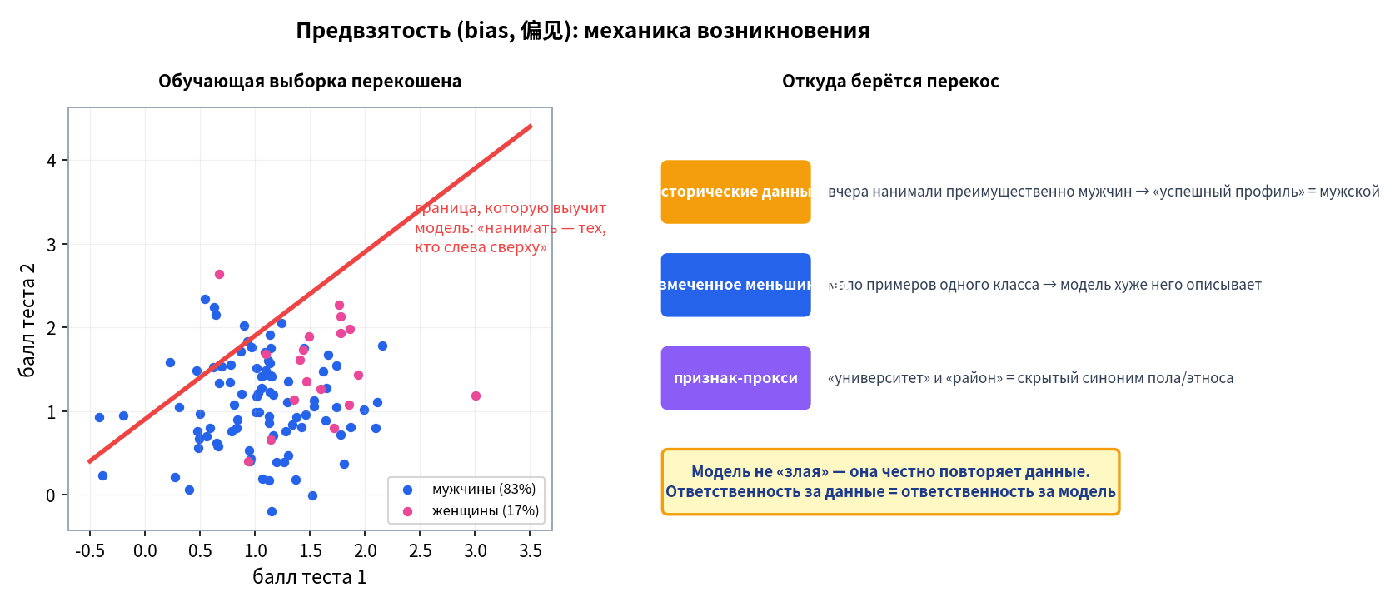

Классические механизмы попадания предвзятости:


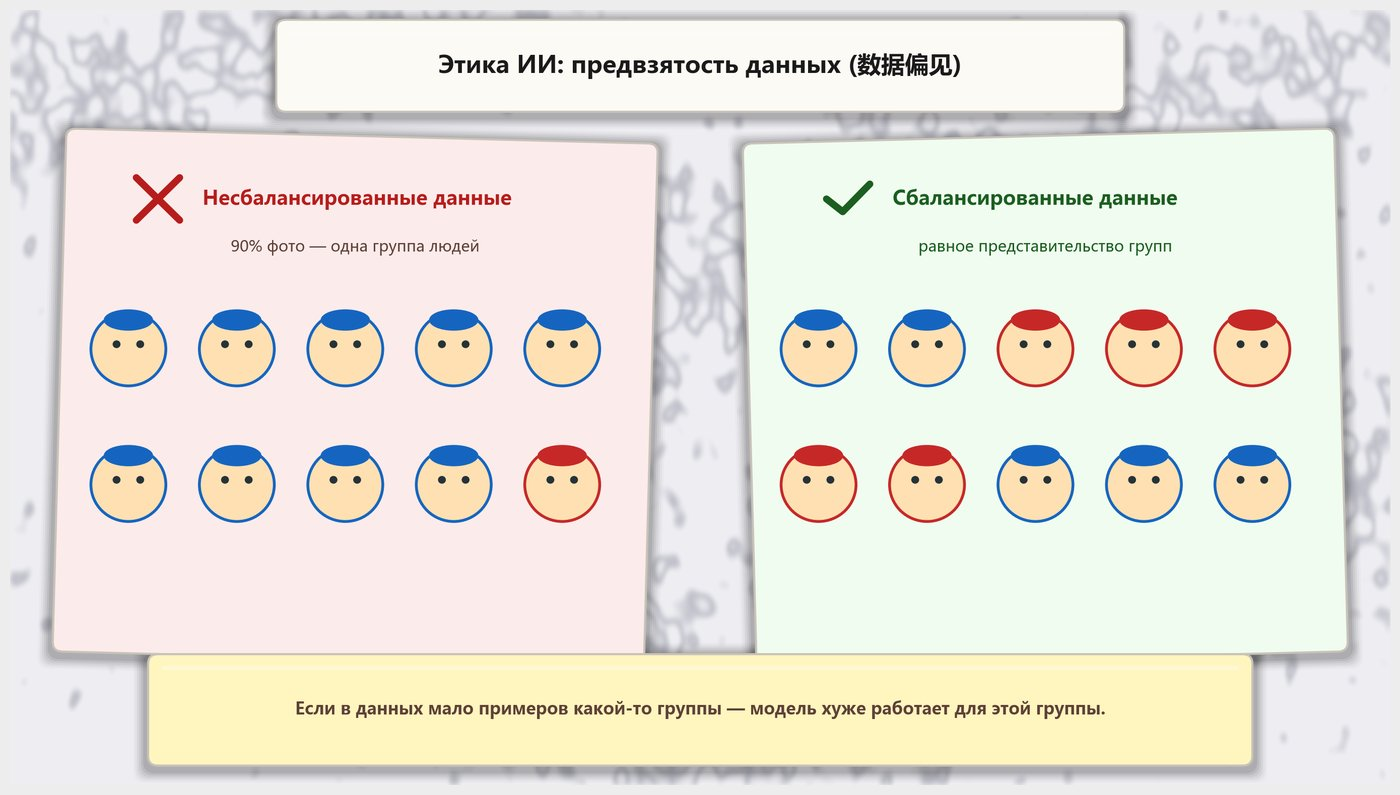

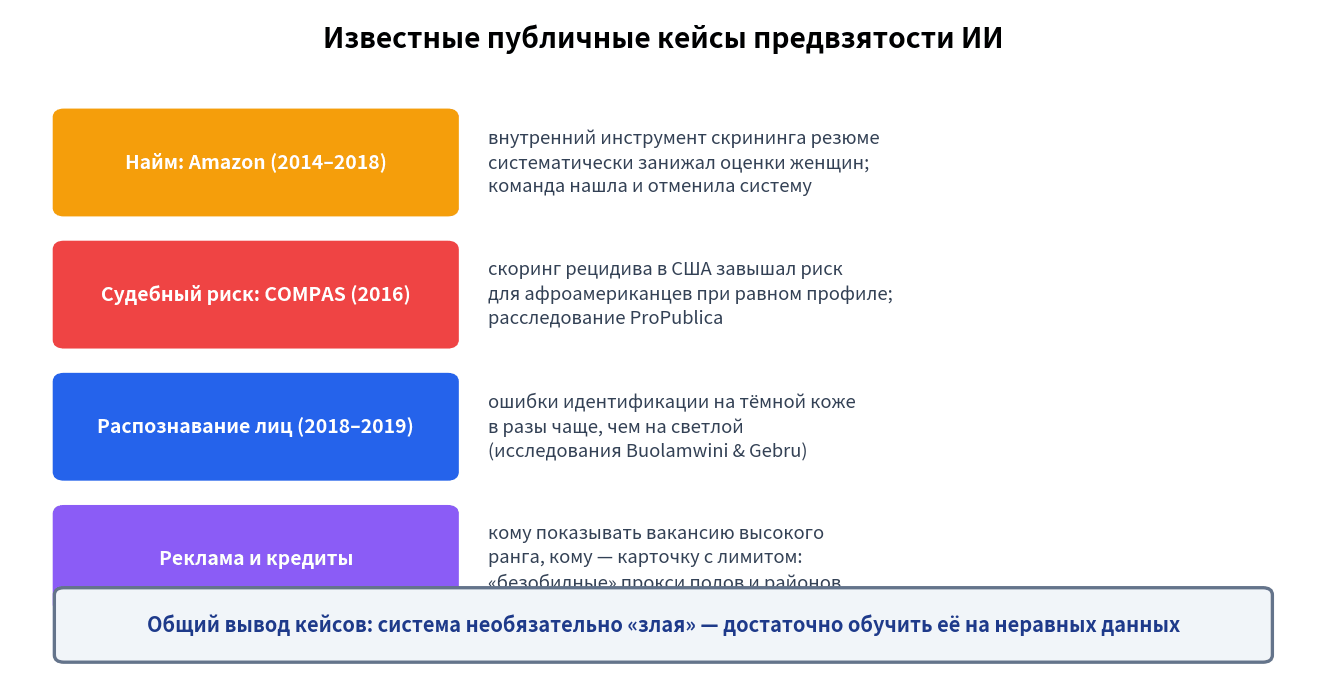

Что делать инженеру (практика, а не мораль):

1. **Смотреть на разрезы**: считать метрики не только «в среднем», но и по группам (пол, район, возраст). В sklearn — `classification_report` по подгруппам.
2. **Проверять признаки-прокси**: «индекс района» может быть синонимом этноса; спросите себя, что признак кодирует на самом деле.
3. **Балансировать выборку и разметку**: у разметчиков тоже есть предвзятость; инструкции и контроль двойной разметкой помогают.
4. **Зафиксировать ограничения** в документации модели: для кого она валидна, для кого нет.



### 📰 Кейс: система отбора резюме Amazon (2014–2017)

Amazon разрабатывала систему ранжирования резюме и обнаружила, что она систематически **занижала оценки кандидатам-женщинам**: модель училась на резюме прошлых лет, когда в технические роли нанимали преимущественно мужчин, и честно воспроизвела этот перекос. «Злой воли» не было — был дисбаланс данных.

Уроки кейса — ровно четыре приёма выше: проверять, **кто и что представлено в выборке**; считать метрики **по группам**; отслеживать признаки-прокси (пол в резюме, название женского колледжа, фраза «соревнования среди девушек» в навыках — модель могла скрыто кодировать пол). Проект в итоге закрыли.


In [ ]:
# Разрез метрик по группам — 10 строк, которые ловят несправедливость
y_true = np.array([1,0,1,1,0,1,0,1,1,0, 1,0,1,0,0,1,1,0,1,1])
y_pred = np.array([1,0,1,0,0,1,0,1,0,0, 1,0,0,0,0,1,1,0,1,0])
group  = np.array(["A"]*10 + ["B"]*10)          # например, две площадки стажировки

import pandas as pd
from sklearn.metrics import recall_score
rows = []
for g in ["A", "B"]:
    m = group == g
    rows.append({"группа": g, "recall": recall_score(y_true[m], y_pred[m]),
                 "доля положительных": y_true[m].mean()})
print(pd.DataFrame(rows))
print("\nРазница recall между группами > 0.15 — повод разбираться до релиза")

  группа    recall  доля положительных
0      A  0.666667                 0.6
1      B  0.666667                 0.6

Разница recall между группами > 0.15 — повод разбираться до релиза


## 2. Приватность: три уровня чувствительности


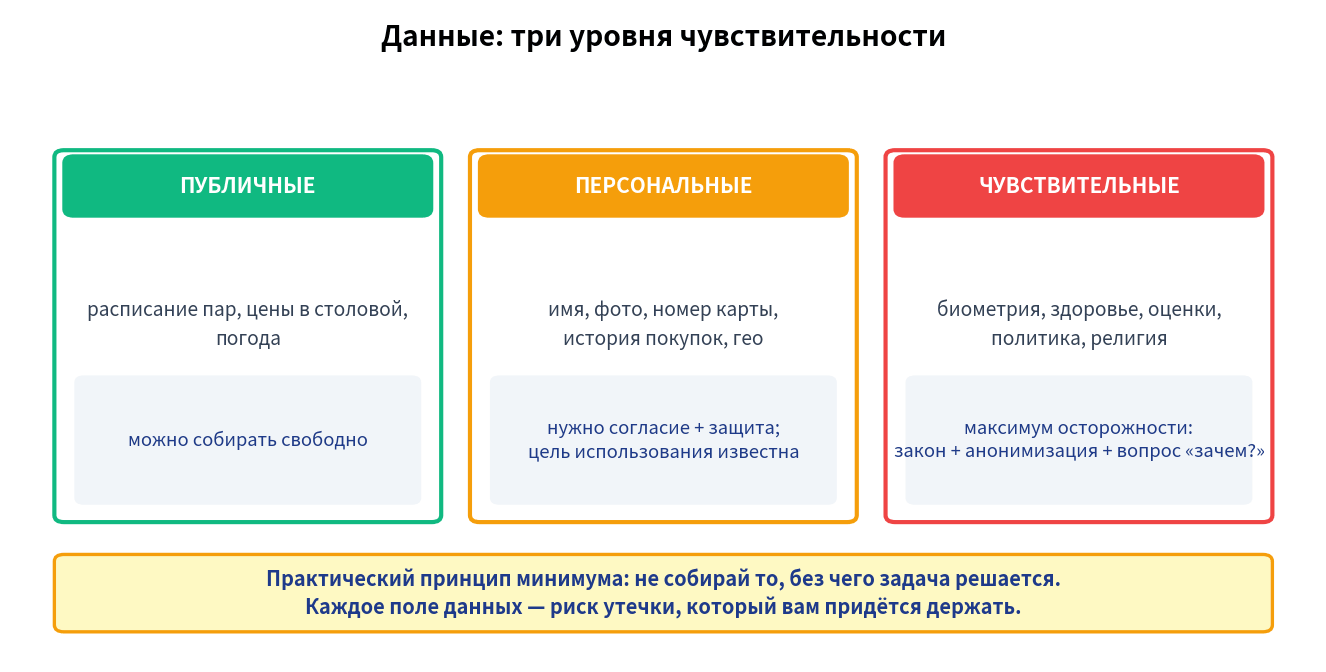

Практическая гигиена данных (то, что проверяют и в вузах, и в компаниях):

- **принцип минимума**: каждое поле данных — потенциальная утечка; не берите без необходимости;
- **согласие и цель**: человек знает, что собирают, и зачем; «согласие» скачанное мелким шрифтом — плохая защита;
- **анонимизация осторожно**: удаление имени недостаточно — комбинация «дата рождения + район + вуз» часто уникальна (реидентификация);
- **локализация**: где хранятся данные студентов — вопрос не технический, а договорной и правовой; для учебных проектов: синтетика и открытые датасеты прежде всего.


## 3. Дипфейки и ИИ-фишинг: атака убедительностью


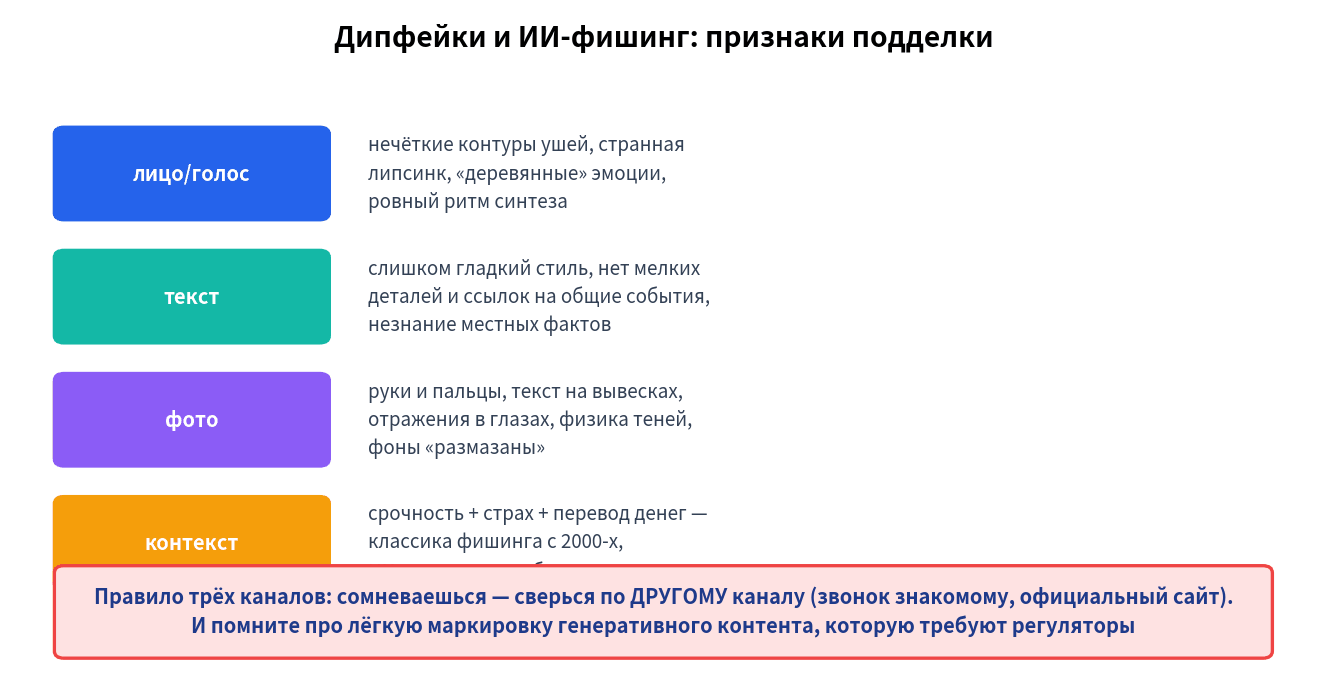

Генеративные модели снизили порог подделки голоса и видео до ноутбучных мощностей. Классический сценарий атаки: «видеозвонок от руководителя — срочно перевести деньги». Защита — не «увидеть подделку глазами» (модели быстро улучшаются), а **процедуры**: второй канал подтверждения, кодовое слово, правило «переводы — только после устного подтверждения по известному номеру». Личная гигиена та же: не публикуйте длинные чистые записи своего голоса и видео.


## 4. Регулирование: риск-подход


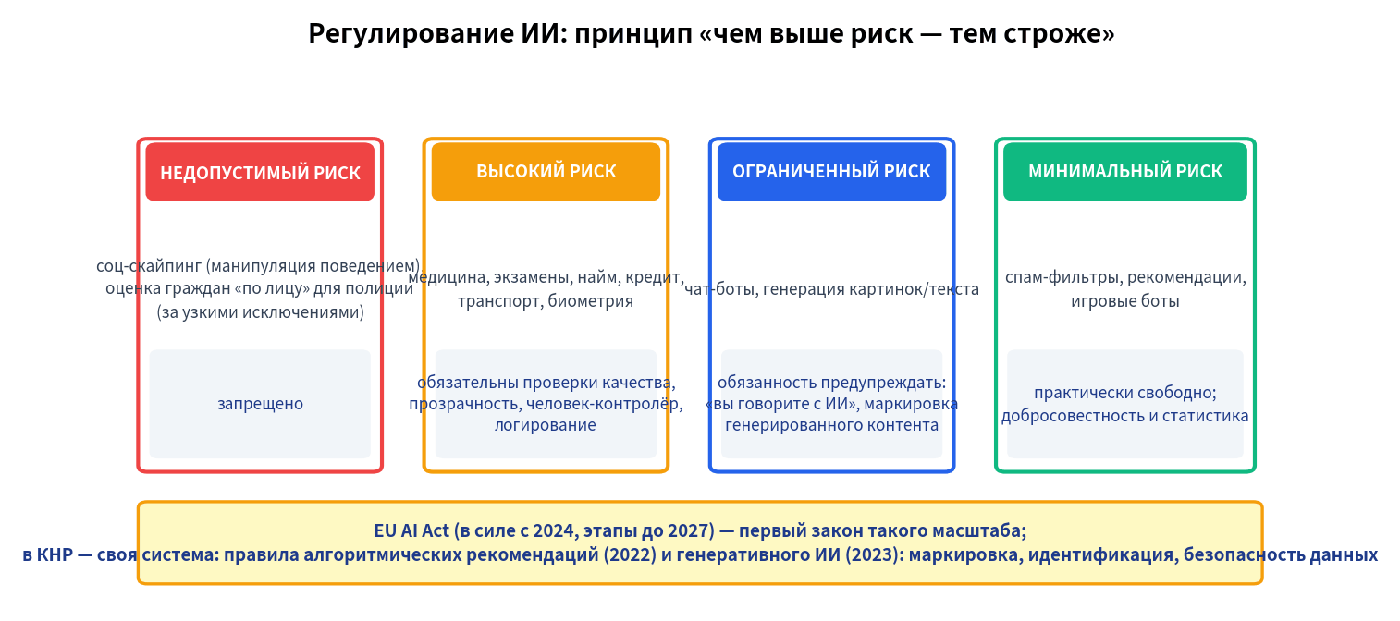

Две крупнейшие системы правил сегодня:

- **EU AI Act** (вступил в силу в 2024, этапы внедрения до 2027): четырёхуровневая пирамида риска — от запрещённых практик (манипуляция поведением, массовый биометрический скайпинг) через «высокий риск» (медицина, найм, экзамены — обязательные проверки качества и прозрачность) к «ограниченному» (чат-боты обязаны представляться, генерированный контент — маркироваться).
- **КНР**: правила алгоритмических рекомендаций (2022) и «Меры по генеративному ИИ» (2023): регистрация сервисов, маркировка сгенерированного контента, требования к качеству обучающих данных и защите персональных данных; отраслевые положения для медицины и образования.

Инженеру из этой лекции нужно главное: **для «высокорисковых» применений модели — тесты, прозрачность и человек в контуре — это не советы, а требования закона**. И тренд один: маркировка генеративного контента становится нормой везде.


## 5. Человек в контуре и ответственность


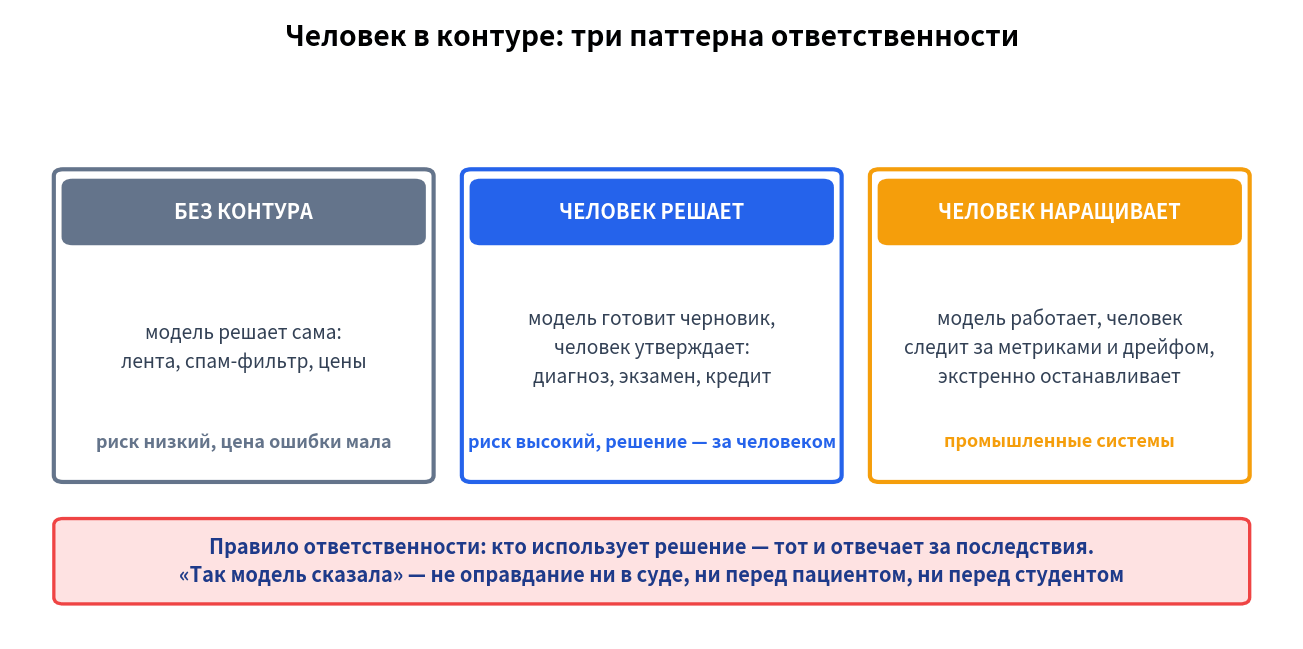

Формула ответственности проста и жёстка: **решает человек — отвечает человек; «модель сказала» не является оправданием**. В high-risk применениях (диагноз, экзамен, кредит) позиция модели — «черновик для решения», финальная подпись — человеческая. Обратное тоже верно: полный запрет ИИ там, где он надёжен, отнимает у людей пользу. Инженерная зрелость — уметь выбрать паттерн под риск.


## 6. Итоги: карта маршрута и что дальше


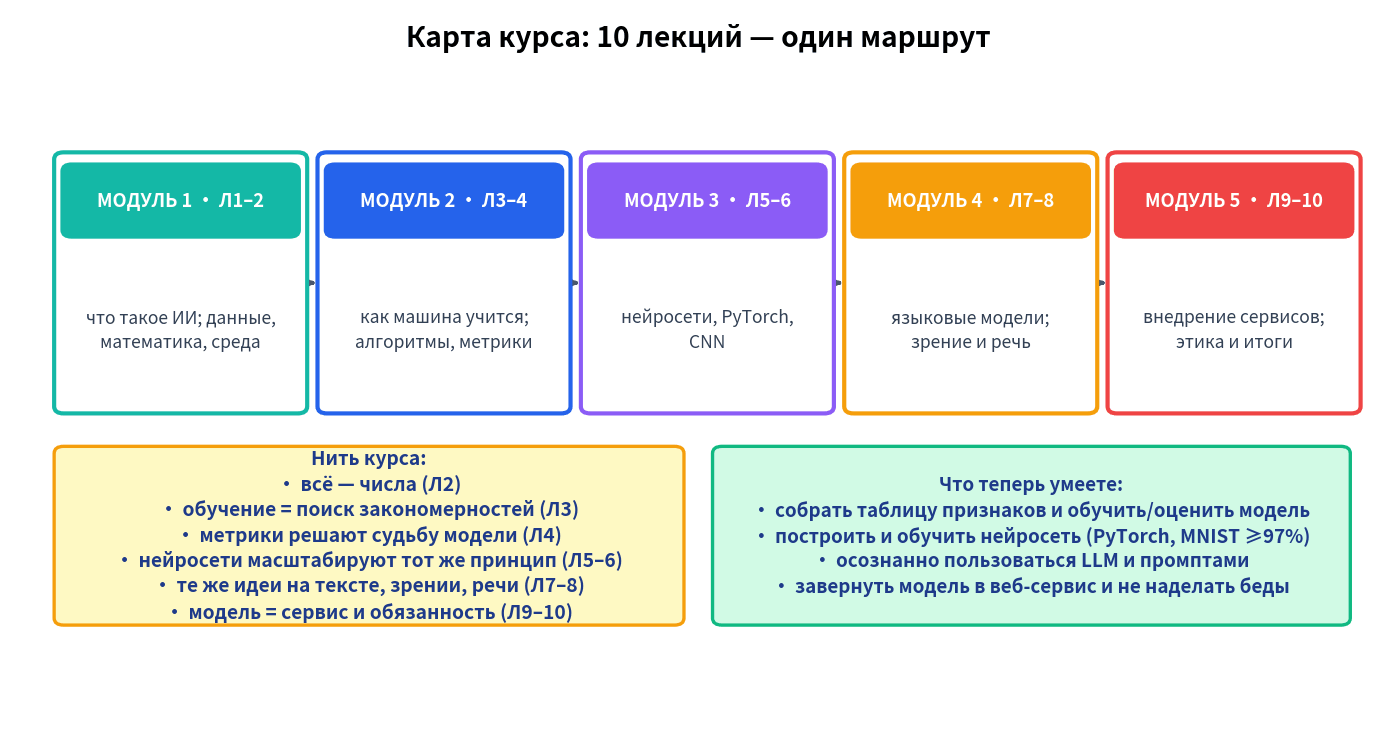


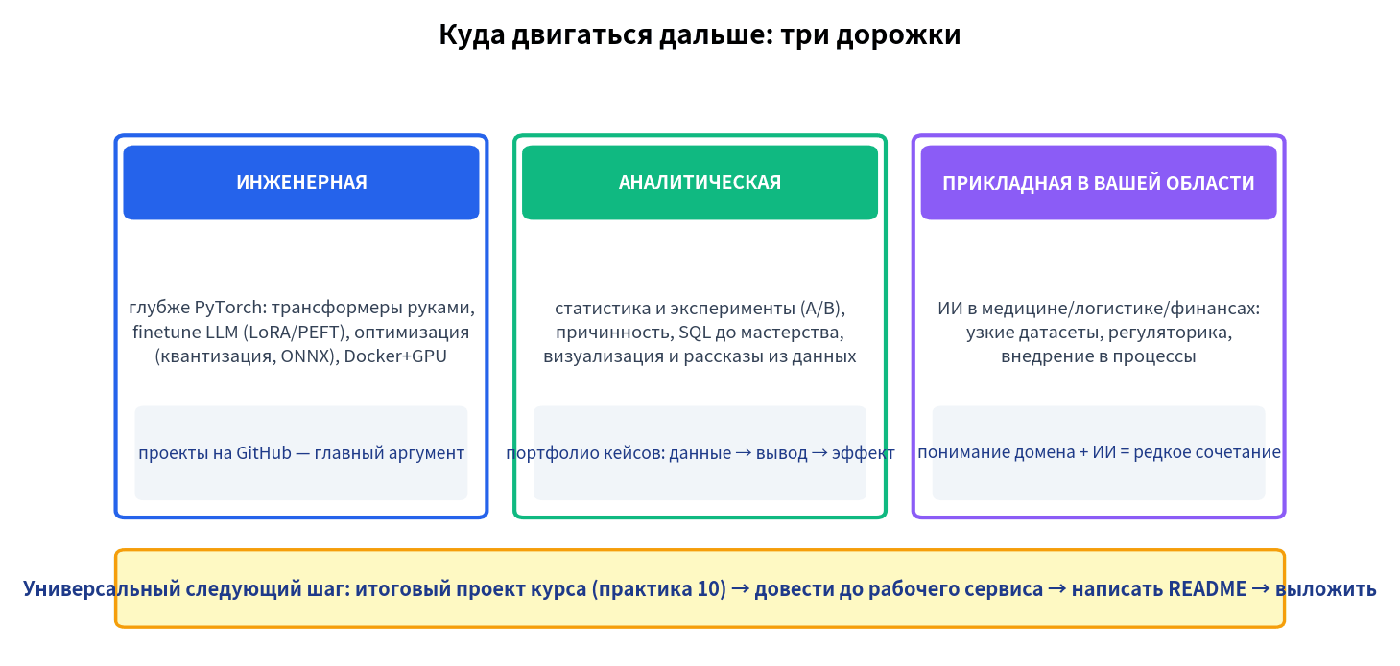



### 🧭 Куда двигаться дальше

- **Углубляйте математику по мере встречных вопросов** — не «про запас», а под конкретную задачу.
- **Соревнования Kaggle и Tianchi (阿里天池)** — бесплатные данные, честный рейтинг, реальные задачи компаний; лучший тренажёр после курса.
- **Читайте документацию библиотек** вместо пересказов блогов — там правда и свежесть.
- **Собирайте портфолио из трёх–пяти проектов** — наш курс уже дал два: распознаватель цифр и веб-сервис к нему.
- И главное — **практикуйтесь**: каждая задача, решённая своими руками, превращает чужие знания в ваши.


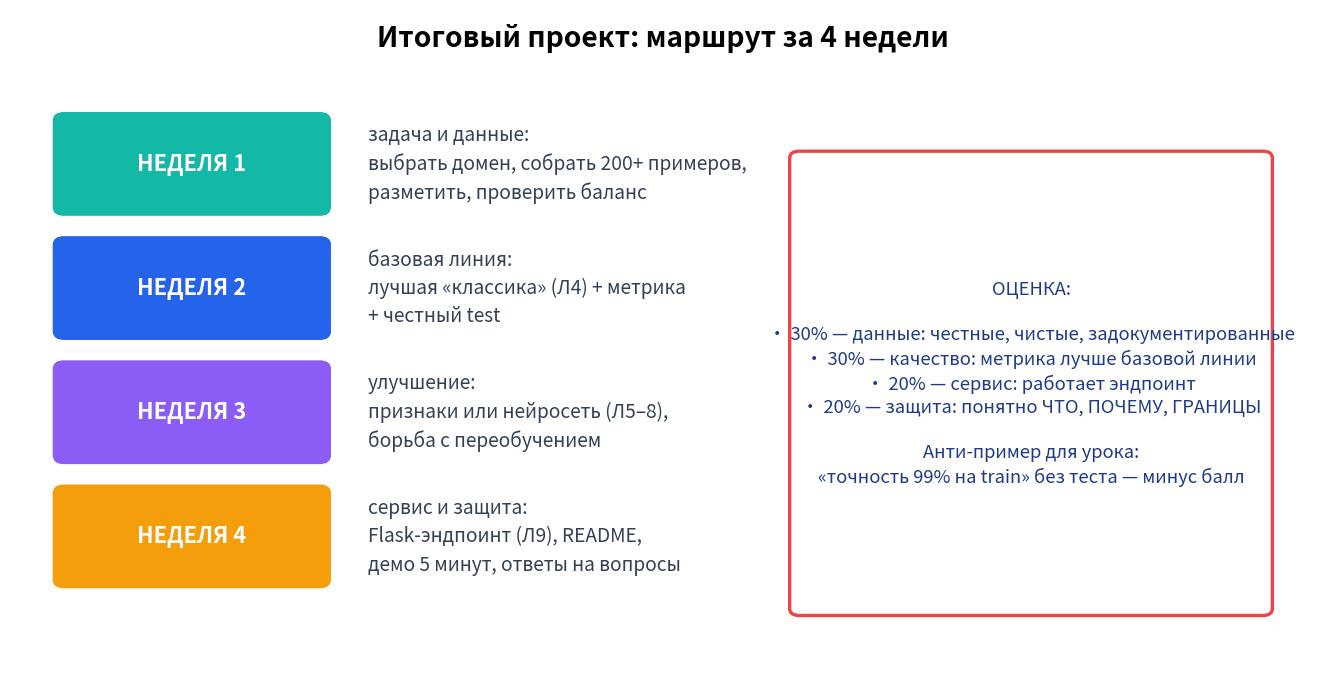

**Финальное слово.** Вы прошли путь от «что такое ИИ» до «как не навредить». Сильный специалист отличается не количеством выученных библиотек, а привычкой задавать три вопроса: **из чего это обучено? на ком это проверяли? кто отвечает, если ошибётся?** Задавайте их — и на собеседованиях, и в своих проектах.


---
## 🎬 Все видеоматериалы лекции 10

### 🇷🇺 РУС · русскоязычные видео (6)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Что полезного сделал ИИ? [Veritasium / Vert Dider] (итоговый ракурс)](https://rutube.ru/video/c6c01be661f65b1feabe0f069bf6fb9c/)<br>· ориг.: *What has AI actually done?* | Vert Dider (VK/Rutube) | 23 мин | Л10 §6: баланс пользы и рисков — итог курса  X |
| 2 | [«Этика и правовые проблемы искусственного интеллекта»](https://stepik.org/course/118318) | Stepik | Stepik / RU | ≈3,4 ч видео, бесплатно ·[добавлено] | ✓ |
| 3 | [Введение в право и этику искусственного интеллекта](https://vkvideo.ru/video-205893390_456239237) | VK · VK-ЭТ | 41:36 | Л10 §4: регулирование — риск-подход · | X |
| 4 | [Елена Брызгалина — «Этика искусственного интеллекта»](https://vkvideo.ru/video-226174019_456239130) | VK · VK-ЭТ | 58:26 | Л10: ключевые этические проблемы (обзорная лекция) ·[добавлено] | X |
| 5 | [Лекция #19. Этика при работе данных и ответственность ИИ. Анна Бергер](https://vkvideo.ru/video-176084509_456240854) | VK · Лекц.ИИ | 51:29 | Л10: предвзятость, приватность, ответственность ИИ ·[добавлено] | X |
| 6 | [Лекция. Последствия релиза GPT - 2](https://vkvideo.ru/video-155161349_456239276) | VK · DLS-2 | 18:14 | Л10 §3: дипфейки и ИИ-фишинг — риски генеративных моделей ·[добавлено] | X |

### 🇨🇳 中文 · китайскоязычные видео (9)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Когнитивные способности больших моделей: ограничения](https://www.bilibili.com/video/BV1UG411p7zv?p=136)<br>· ориг.: *9-14 大模型认知能力--挑战与限制* | Bilibili · 清华NLP | 1 мин | Л10 §1–3: пределы LLM | ✓ |
| 1 | [李宏毅（2025）：来自人类的恶意攻击](https://www.bilibili.com/video/BV1YdegzsEmr?p=39) | Bilibili · 李宏毅 DL | Bilibili / ZH | 30 мин (?p=39–43) · | ✓ |
| 1 | [深度伪造：技术原理 и 如何防范AI诈骗](https://www.bilibili.com/video/BV1WVfGYfE2U) | Bilibili · дипфейки | Bilibili / ZH | 8 + 10 мин · | ✓ |




### 🇬🇧 EN · англоязычные видео (6)

| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 |  [Этика искусственного интеллекта 哈佛教授桑德尔北大开讲：机器人是否会取代人类？](https://www.bilibili.com/video/BV1FrX7YWEuZ) | Bilibili · Сэндел | Bilibili / ZH | 2 ч 12 мин, 14,5 тыс. · | ✓ |
| 2 | [Andrew Ng и Ли Фэйфэнь: ИИ, ориентированный на человека](https://www.bilibili.com/video/BV1owrpYKEtP?p=37)<br>· ориг.: *37.吴恩达与李飞飞谈以人为本的AI (речь — английская)* | Bilibili · 吴恩达 | 41 мин | Л10 §5: человек в контуре | ✓ |
| 3 | [Andrew Ng и Челси Финн: ИИ и робототехника (итоговая беседа)](https://www.bilibili.com/video/BV1owrpYKEtP?p=146)<br>· ориг.: *146.吴恩达与切尔西·芬恩谈AI与机器人 (речь — английская)* | Bilibili · 吴恩达 | 33 мин | Л10 §6: куда движется область | ✓ |
| 4 | [Andrew Ng: Справедливость, предвзятость и этика](https://www.bilibili.com/video/BV1owrpYKEtP?p=84)<br>· ориг.: *84.公平性、偏见与伦理 (речь — английская)* | Bilibili · 吴恩达 | 9 мин | Л10 §1: bias в данных и моделях | ✓ |
| 5 | [TED：Как я борюсь с предвзятостью алгоритмов 我如何与算法偏见对抗（Joy Buolamwini）](https://www.bilibili.com/video/BV1bt411H7g5) | Bilibili · TED bias | Bilibili / EN+中字 | 17 мин ·[добавлено] | ✓ |
| 6 | [Безопасность искусственного интеллекта, этика и общество 加州大学伯克利分校《AI Safety, Ethics & Society》](https://www.bilibili.com/video/BV1D3NwzHEkd) | Bilibili · Berkeley AI Safety | Bilibili / EN+中字 | 8 лекций, ≈7 ч ·[добавлено] | ✓ |



### Контрольные вопросы (итоговый срез по курсу)

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Назовите три механизма попадания предвзятости в модель из этой лекции.**
<details>
<summary>Показать ответ</summary>
<b>1.</b> Перекошенная выборка — в данных мало примеров какой-то группы (кейс Amazon: прошлые нанимали преимущественно мужчин); <b>2.</b> предвзятость разметчиков — их инструкции и привычки воспроизводятся в метках; <b>3.</b> признаки-прокси — «название женского колледжа» скрыто кодирует пол, даже если пол убрали.
</details>

**2. Почему удаление имён из таблицы не делает её анонимной?**
<details>
<summary>Показать ответ</summary>
Косвенные поля в комбинации уникальны: <b>«дата рождения + район + вуз»</b> часто указывают на одного человека — это реидентификация. Настоящая анонимизация — агрегация данных и принцип минимума, а не удаление одного столбца.
</details>

**3. Сомнительный «звонок руководителя» о переводе денег: процедура или распознавание голоса защищает надёжнее?**
<details>
<summary>Показать ответ</summary>
<b>Процедура.</b> Второй канал подтверждения, кодовое слово и правило «переводы — только после звонка по известному номеру» не зависят от качества подделки. Распознавание голоса не спасает: дипфейк создаётся по 5–10 секундам записи, и модели улучшаются быстрее, чем «натренированный глаз».
</details>

**4. Ваш сервис помогает приёмной комиссии ранжировать абитуриентов. Какой уровень риска по пирамиде? Что обязательно по закону?**
<details>
<summary>Показать ответ</summary>
<b>Высокий риск</b>: найм и образование стоят высоко в пирамиде EU AI Act. Обязательно: тесты качества модели, прозрачность и объяснимость решений, <b>человек-контролёр</b> за финальным решением — это не советы, а требования закона.
</details>

**5. Модель медицины предлагает лечение. Какой паттерн человека в контуре обязателен?**
<details>
<summary>Показать ответ</summary>
<b>«Человек утверждает решение»</b>: модель готовит черновик-рекомендацию, а финальную подпись ставит врач. В high-risk применениях (диагноз, экзамен, кредит) «модель сказала» не является оправданием — решает и отвечает человек.
</details>

**6. По карте курса: какой лекцией закрывается вопрос «на ком проверяли?»**
<details>
<summary>Показать ответ</summary>
<b>Лекции 3–4</b>: честные выборки (train/test, stratify) и метрики качества; <b>лекция 10</b>: разрезы метрик по группам (пол, район, возраст) — «в среднем хорошо» может скрывать провал для группы.
</details>

**7. Что из курса вы примените в дипломе уже в этом семестре? План на 3 пункта.**
<details>
<summary>Показать ответ</summary>
Пример плана: <b>1.</b> собрать и очистить данные для дипломного исследования (60–80% времени — по лекции 3); <b>2.</b> построить простой baseline из scikit-learn до всяких нейросетей (лекция 4); <b>3.</b> проверить метрики по группам и записать ограничения модели (лекция 10). Это личный ответ — главное, чтобы три пункта были конкретными.
</details>


## 📚 Глоссарий Лекции 10 (词汇表)

Термины этики ИИ и регулирования (термины деплоя — в Лекции 9).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| Предвзятость (bias) | Bias | 偏见 | Систематическое отклонение модели; причина — смещённые данные. |
| Приватность | Privacy | 隐私 | Защита персональных данных пользователей; GDPR, PIPL. |
| Чувствительные данные | Sensitive data | 敏感数据 | Данные, требующие особой защиты: здоровье, биометрия, религия. |
| Анонимизация | Anonymization | 匿名化 | Удаление или маскирование идентифицирующей информации из данных. |
| Принцип минимума | Data minimization principle | 数据最小化原则 | Собирать только те данные, что нужны для задачи; не больше. |
| Дипфейк | Deepfake | 深度伪造 | Синтетическая подмена лица/голоса через нейросеть. |
| ИИ-фишинг | AI phishing | 人工智能钓鱼 | Массовый фишинг через LLM; узнают по «второму каналу» проверки. |
| EU AI Act | EU AI Act | 欧盟AI法案 | Европейский закон об ИИ по рискам (2024). |
| Регулирование ИИ в КНР | PRC AI regulation | 中国AI监管 | Правила КНР: маркировка синтетики, безопасность моделей. |
| Маркировка ИИ-контента | AI content labeling | 人工智能内容标识 | Пометка контента как созданного ИИ; требование регуляторов. |
| Человек в контуре | Human-in-the-loop | 人在回路 | Решение принимает человек, а ИИ помогает; обязательно для высокого риска. |
| Ответственность | Accountability | 责任 | Юридическая и моральная; всегда возвращается к человеку, не к модели. |
| Риск-подход | Risk-based approach | 风险分级方法 | Регулирование строго в зависимости от уровня риска применения. |
| AGI | Artificial General Intelligence | 通用人工智能 | Гипотетический ИИ человеческого уровня во всех задачах; не создан. |
| Прозрачность | Transparency | 透明性 | Право пользователя знать, что он общается с ИИ, а не с человеком. |


## 🎓 Итоги Лекции 10

Заключительная лекция свела вместе: предвзятость данных, приватность, дипфейки и ИИ-фишинг, регулирование (EU AI Act, правила КНР), человека в контуре и карту курса от данных до деплоя — как один непрерывный путь.

### 🔑 Главные выводы

1. Предвзятость — свойство данных, а не «злой воли» модели; лечится разрезами метрик, проверкой прокси и балансировкой.
2. Данные: публичные / персональные / чувствительные; принцип минимума и честная анонимизация.
3. Дипфейки и ИИ-фишинг побеждаются процедурами (второй канал), а не «зорким глазом».
4. Регулирование — риск-подход: EU AI Act и правила КНР сходятся в требовании прозрачности и маркировки.
5. Паттерны человека в контуре выбираются по риску; ответственность всегда возвращается к человеку.
6. Курс собран в одну нить: числа → обучение → метрики → нейросети → текст/зрение/речь → сервис → ответственность.

### 📝 Домашнее задание

1. **Аудит справедливости.** Возьмите любой открытый датасет с атрибутом группы (например, Adult). Посчитайте accuracy/precision/recall по группам. Есть ли разрыв > 10 п.п.? Напишите вывод на полстраницы.
2. **Регуляторный разбор.** Ваш итоговый проект — сервис распознавания рукописных цифр. Оцените его уровень риска по пирамиде, обоснуйте, перечислите обязательные требования (или их отсутствие).
3. **План развития.** Выберите одну из трёх дорожек и составьте план на 3 месяца: что учить, какой проект делать, где публиковать. Половина страницы — это ваш контракт с собой.

### 📅 Следующее занятие

**— (заключительная лекция курса пройдена)**

**Практика 10: Итоговый комплексный мини-проект и защита**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>